<a href="https://colab.research.google.com/github/Benja4c/Data-school/blob/main/Machine_learning_Class.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

In [ ]:
iris = load_iris()

x = iris.data
y = iris.target

#Converting the dataset to Dataframe

In [ ]:
df = pd.DataFrame(
    x,
    columns=iris.feature_names

)
df['species'] = y

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


#**Explore Dataset**

In [ ]:
df.info()
df.describe()
df["species"].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


,count
species,
0,50
1,50
2,50


#**Split Dataset**


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42

)


#**Train Three Models**

Topics covered:

What is the famous iris dataset, and how does it relate to Machine Learning?

How do we load the iris dataset into scikit-learn?

How do we describe a dataset using Machine Learning terminology?

What are scikit-learn's four key requirements for working with data?

Topics covered:

What is the K-nearest neighbors classification model?

What are the four steps for model training and prediction in scikit-learn?

How can I apply this pattern to other Machine Learning models?

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

models = {
    "Logistic Regression": LogisticRegression(max_iter=200),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "KNN": KNeighborsClassifier()

}

results = {}

for name, model in models.items():
  model.fit(X_train, y_train)
  accuracy = model.score(X_test, y_test)
  results[name] = accuracy



#**Compare REsults**

In [ ]:
results_df = pd.DataFrame(
    results.items(),
    columns=["Model", "Accuracy"]


)

results_df

,Model,Accuracy
0,Logistic Regression,1.0
1,Decision Tree,1.0
2,KNN,1.0


#**Plot Model Performance**

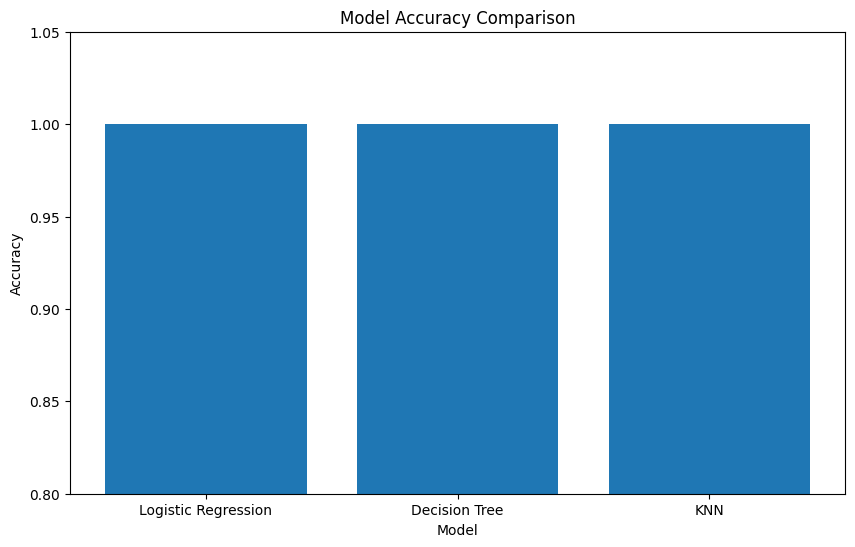

In [ ]:
plt.figure(figsize=(10,6))

plt.bar(
    results_df["Model"],
    results_df["Accuracy"],
    #color="orange"
)
plt.ylim(0.8,1.05)
plt.title("Model Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.show()

#**Select the Best Model**

In [ ]:
best_model_name = max(results, key=results.get)
print(best_model_name)
best_model = models[best_model_name]

Logistic Regression


#**Make Prediction**

In [ ]:
prediction = best_model.predict(X_test)
#
print("Predicted Species:", iris.target_names[prediction[:10]])

Predicted Species: ['versicolor' 'setosa' 'virginica' 'versicolor' 'versicolor' 'setosa'
 'versicolor' 'virginica' 'versicolor' 'versicolor']


#**Evaluate The Best Model**

In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix


)

print("here is the Classification report")
print(classification_report(y_test, prediction))
print("_____________________________________________")
print("here is the Confusion Matrix")
print(confusion_matrix(y_test, prediction))

here is the Classification report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30

_____________________________________________
here is the Confusion Matrix
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


#**Save the est model**

In [ ]:
import joblib
joblib.dump(best_model, "best_iris_model.pkl")

['best_iris_model.pkl']

In [ ]:
loaded_model = joblib.load("best_iris_model.pkl")

In [ ]:
new_flower = [[5.2,3.6,1.5,0.3]]
prediction = loaded_model.predict(new_flower)
print("predicted Species:", iris.target_names[prediction[0]])

predicted Species: setosa
